In [1]:
import sys
from pathlib import Path

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Add the project root to Python's import path
PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR))

# Import our reusable modules
from src.data_loader import load_prepared_data
from src.models.rnn_model import RNNModel
from src.training import train_model

In [2]:
# Set random seed for reproducibility
SEED = 42
torch.manual_seed(SEED)

# Configure device and batch size
device = torch.device("cpu")
BATCH_SIZE = 32

# Load the previously prepared datasets
tensor_path = PROJECT_DIR / "data" / "tensors" / "electricity_sequences.pt"

train_loader, val_loader, test_loader = load_prepared_data(
    tensor_path,
    batch_size=BATCH_SIZE
)

# Verify dataset sizes and input dimensions
X_batch, y_batch = next(iter(train_loader))

print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Input shape:", X_batch.shape)
print("Target shape:", y_batch.shape)

Device: cpu
Training batches: 2190
Validation batches: 1095
Test batches: 1095
Input shape: torch.Size([32, 96, 1])
Target shape: torch.Size([32, 1])


In [3]:
# RNN architecture
INPUT_SIZE = 1
HIDDEN_SIZE = 32
NUM_LAYERS = 2

# Training configuration
LEARNING_RATE = 0.001
NUM_EPOCHS = 20
PATIENCE = 5

# Initialise the RNN model
rnn_model = RNNModel(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
).to(device)

# Loss function: Mean Squared Error
criterion = nn.MSELoss()

# Optimiser: Adam
rnn_optimizer = torch.optim.Adam(
    rnn_model.parameters(),
    lr=LEARNING_RATE
)

# Path for saving the best RNN checkpoint
rnn_checkpoint = PROJECT_DIR / "models" / "best_rnn.pt"

# Display model architecture and parameter count
print(rnn_model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
)

RNNModel(
  (rnn): RNN(1, 32, num_layers=2, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

Trainable parameters: 3265


In [4]:
# Train the RNN with early stopping and best-model checkpointing
rnn_history = train_model(
    model=rnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=rnn_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=rnn_checkpoint,
    patience=PATIENCE,
)

Epoch [1/20] Train Loss: 0.056664 | Val Loss: 0.051422
  Best model saved.
Epoch [2/20] Train Loss: 0.043656 | Val Loss: 0.049486
  Best model saved.
Epoch [3/20] Train Loss: 0.041094 | Val Loss: 0.047351
  Best model saved.
Epoch [4/20] Train Loss: 0.039858 | Val Loss: 0.046279
  Best model saved.
Epoch [5/20] Train Loss: 0.038786 | Val Loss: 0.045004
  Best model saved.
Epoch [6/20] Train Loss: 0.038734 | Val Loss: 0.048335
Epoch [7/20] Train Loss: 0.037891 | Val Loss: 0.047143
Epoch [8/20] Train Loss: 0.038938 | Val Loss: 0.045995
Epoch [9/20] Train Loss: 0.038141 | Val Loss: 0.046271
Epoch [10/20] Train Loss: 0.038784 | Val Loss: 0.045192
Early stopping at epoch 10. Best validation loss: 0.045004


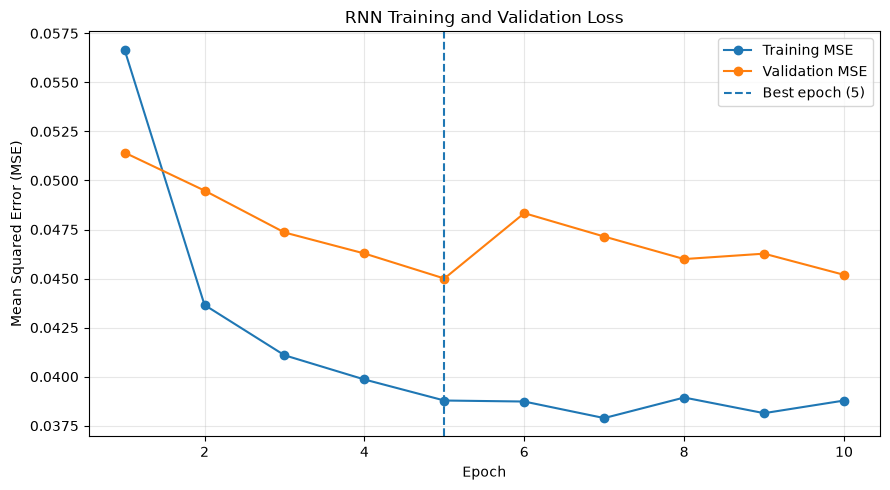

In [5]:
# Plot RNN training and validation losses
epochs = range(1, len(rnn_history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    rnn_history["train_loss"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    epochs,
    rnn_history["val_loss"],
    marker="o",
    label="Validation MSE"
)

# Mark the epoch with the lowest validation loss
best_epoch = min(
    range(len(rnn_history["val_loss"])),
    key=lambda i: rnn_history["val_loss"][i]
) + 1

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("RNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Reload the RNN weights from the best validation epoch
rnn_model.load_state_dict(
    torch.load(
        rnn_checkpoint,
        map_location=device,
        weights_only=True
    )
)

# Switch to evaluation mode
rnn_model.eval()

print("Best RNN checkpoint loaded successfully.")
print("Checkpoint:", rnn_checkpoint)

Best RNN checkpoint loaded successfully.
Checkpoint: c:\Users\sy_be\Projects\Electricity-Forecasting-PyTorch\models\best_rnn.pt


In [7]:
import joblib

from src.evaluation import generate_predictions, calculate_metrics

# Load the scaler fitted on training data only
scaler_path = (
    PROJECT_DIR / "data" / "tensors" / "consumption_scaler.pkl"
)
scaler = joblib.load(scaler_path)

# Generate predictions using our best RNN checkpoint
rnn_predictions, rnn_targets = generate_predictions(
    model=rnn_model,
    data_loader=test_loader,
    device=device,
)

# Calculate metrics in the original consumption units
rnn_metrics = calculate_metrics(
    predictions=rnn_predictions,
    targets=rnn_targets,
    scaler=scaler,
)

# Display results
print("RNN Test Results")
print("----------------")
print("Predictions shape:", rnn_predictions.shape)
print("Targets shape:", rnn_targets.shape)

for metric, value in rnn_metrics.items():
    print(f"{metric}: {value:.4f}")

RNN Test Results
----------------
Predictions shape: (35040, 1)
Targets shape: (35040, 1)
MAE: 0.1184
MSE: 0.0455
RMSE: 0.2133


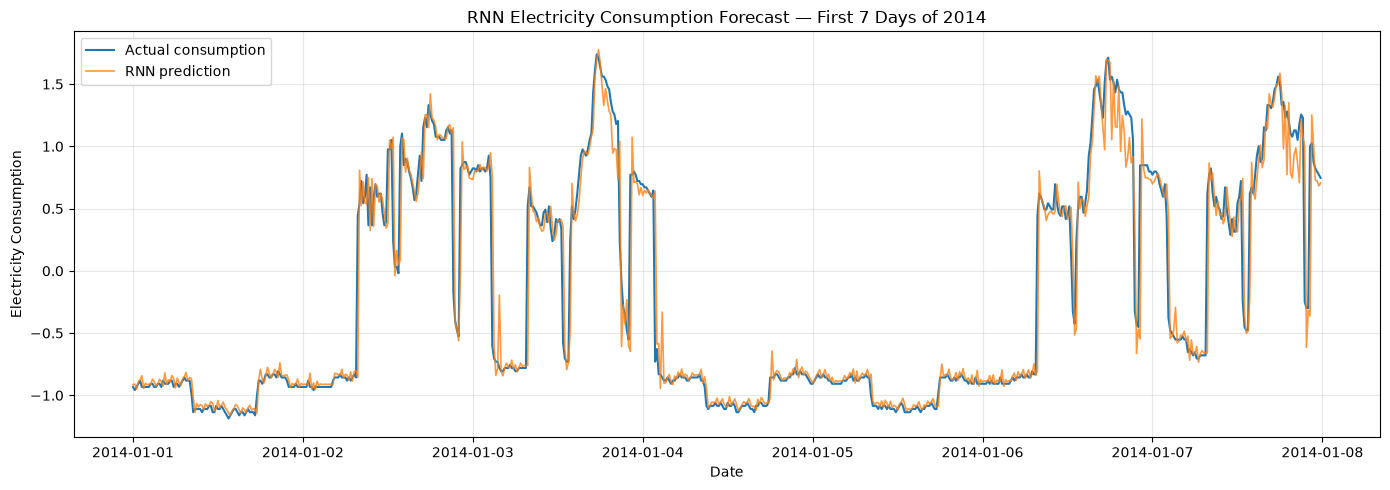

In [9]:
import pandas as pd

# Convert predictions and targets to their original scale
rnn_pred_original = scaler.inverse_transform(rnn_predictions)
rnn_actual_original = scaler.inverse_transform(rnn_targets)

# First seven days: 7 * 24 * 4 = 672 observations
n_points = 672

# Test timestamps correspond to the prediction targets
test_timestamps = pd.date_range(
    start="2014-01-01",
    periods=n_points,
    freq="15min"
)

plt.figure(figsize=(14, 5))

plt.plot(
    test_timestamps,
    rnn_actual_original[:n_points, 0],
    label="Actual consumption",
    linewidth=1.5
)

plt.plot(
    test_timestamps,
    rnn_pred_original[:n_points, 0],
    label="RNN prediction",
    linewidth=1.2,
    alpha=0.8
)

plt.title("RNN Electricity Consumption Forecast — First 7 Days of 2014")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Retrieve all test input sequences and targets
X_test = test_loader.dataset.tensors[0].numpy()
y_test = test_loader.dataset.tensors[1].numpy()

# Persistence prediction: use the final observation of each sequence
persistence_predictions = X_test[:, -1, :]

# Convert predictions and targets to original scale
persistence_original = scaler.inverse_transform(persistence_predictions)
targets_original = scaler.inverse_transform(y_test)

# Calculate baseline metrics
persistence_mae = mean_absolute_error(
    targets_original, persistence_original
)

persistence_mse = mean_squared_error(
    targets_original, persistence_original
)

persistence_rmse = np.sqrt(persistence_mse)

print("Persistence Baseline Test Results")
print("---------------------------------")
print(f"MAE:  {persistence_mae:.4f}")
print(f"MSE:  {persistence_mse:.4f}")
print(f"RMSE: {persistence_rmse:.4f}")

Persistence Baseline Test Results
---------------------------------
MAE:  0.0935
MSE:  0.0399
RMSE: 0.1998


## LSTM Model

In [11]:
from src.models.lstm_model import LSTMModel

# Reset random seed for reproducibility
torch.manual_seed(SEED)

# Initialise the LSTM using the same configuration as the RNN
lstm_model = LSTMModel(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
).to(device)

# Use the same learning rate and optimiser type
lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=LEARNING_RATE
)

# Save the best LSTM checkpoint separately
lstm_checkpoint = PROJECT_DIR / "models" / "best_lstm.pt"

print(lstm_model)
print(
    "\nTrainable parameters:",
    sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)
)

LSTMModel(
  (lstm): LSTM(1, 32, num_layers=2, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

Trainable parameters: 12961


In [12]:
# Train LSTM using the same configuration as the RNN
lstm_history = train_model(
    model=lstm_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=lstm_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=lstm_checkpoint,
    patience=PATIENCE,
)

Epoch [1/20] Train Loss: 0.069916 | Val Loss: 0.050788
  Best model saved.
Epoch [2/20] Train Loss: 0.041165 | Val Loss: 0.045389
  Best model saved.
Epoch [3/20] Train Loss: 0.037328 | Val Loss: 0.043740
  Best model saved.
Epoch [4/20] Train Loss: 0.035503 | Val Loss: 0.044698
Epoch [5/20] Train Loss: 0.034454 | Val Loss: 0.042684
  Best model saved.
Epoch [6/20] Train Loss: 0.033541 | Val Loss: 0.043679
Epoch [7/20] Train Loss: 0.032653 | Val Loss: 0.043789
Epoch [8/20] Train Loss: 0.032184 | Val Loss: 0.042742
Epoch [9/20] Train Loss: 0.031625 | Val Loss: 0.042139
  Best model saved.
Epoch [10/20] Train Loss: 0.030873 | Val Loss: 0.044781
Epoch [11/20] Train Loss: 0.030614 | Val Loss: 0.043166
Epoch [12/20] Train Loss: 0.030043 | Val Loss: 0.041120
  Best model saved.
Epoch [13/20] Train Loss: 0.029528 | Val Loss: 0.042211
Epoch [14/20] Train Loss: 0.029220 | Val Loss: 0.041921
Epoch [15/20] Train Loss: 0.029166 | Val Loss: 0.041995
Epoch [16/20] Train Loss: 0.028793 | Val Loss: 0.

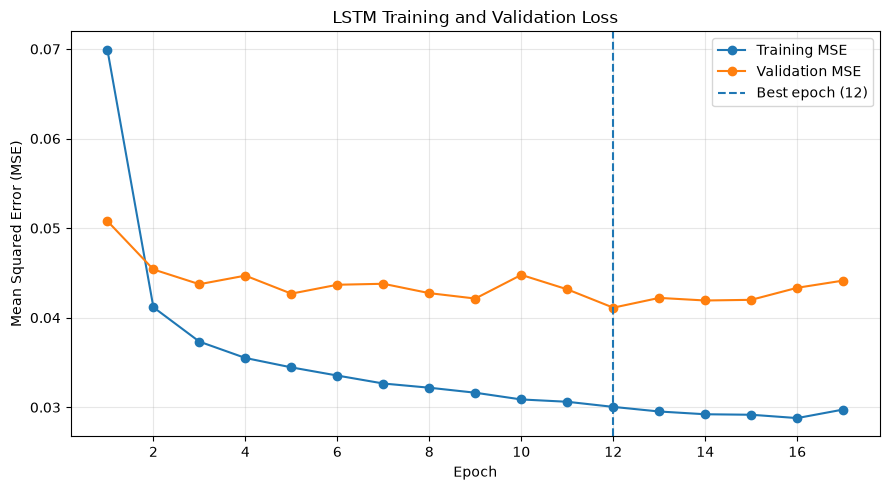

In [13]:
# Plot LSTM training and validation losses
epochs = range(1, len(lstm_history["train_loss"]) + 1)

best_epoch = (
    lstm_history["val_loss"].index(
        min(lstm_history["val_loss"])
    ) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    lstm_history["train_loss"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    epochs,
    lstm_history["val_loss"],
    marker="o",
    label="Validation MSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Restore the best LSTM weights (epoch 12)
lstm_model.load_state_dict(
    torch.load(
        lstm_checkpoint,
        map_location=device,
        weights_only=True
    )
)

# Switch to evaluation mode
lstm_model.eval()

print("Best LSTM checkpoint loaded successfully.")
print("Checkpoint:", lstm_checkpoint)

Best LSTM checkpoint loaded successfully.
Checkpoint: c:\Users\sy_be\Projects\Electricity-Forecasting-PyTorch\models\best_lstm.pt


In [15]:
# Generate LSTM predictions on the test dataset
lstm_predictions, lstm_targets = generate_predictions(
    model=lstm_model,
    data_loader=test_loader,
    device=device,
)

# Calculate metrics in the original consumption scale
lstm_metrics = calculate_metrics(
    predictions=lstm_predictions,
    targets=lstm_targets,
    scaler=scaler,
)

# Display results
print("LSTM Test Results")
print("-----------------")
print("Predictions shape:", lstm_predictions.shape)
print("Targets shape:", lstm_targets.shape)

for metric, value in lstm_metrics.items():
    print(f"{metric}: {value:.4f}")

LSTM Test Results
-----------------
Predictions shape: (35040, 1)
Targets shape: (35040, 1)
MAE: 0.1313
MSE: 0.0505
RMSE: 0.2247


## GRU Model

In [16]:
from src.models.gru_model import GRUModel

# Reset the random seed for reproducibility
torch.manual_seed(SEED)

# Initialise GRU with the same architecture dimensions
gru_model = GRUModel(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
).to(device)

# Use the same optimiser and learning rate
gru_optimizer = torch.optim.Adam(
    gru_model.parameters(),
    lr=LEARNING_RATE
)

# Save the best GRU checkpoint separately
gru_checkpoint = PROJECT_DIR / "models" / "best_gru.pt"

# Inspect architecture and parameter count
print(gru_model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in gru_model.parameters() if p.requires_grad)
)

GRUModel(
  (gru): GRU(1, 32, num_layers=2, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)

Trainable parameters: 9729


In [17]:
# Train the GRU using the same configuration as RNN and LSTM
gru_history = train_model(
    model=gru_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=gru_optimizer,
    device=device,
    num_epochs=NUM_EPOCHS,
    checkpoint_path=gru_checkpoint,
    patience=PATIENCE,
)

Epoch [1/20] Train Loss: 0.059766 | Val Loss: 0.051034
  Best model saved.
Epoch [2/20] Train Loss: 0.041998 | Val Loss: 0.047689
  Best model saved.
Epoch [3/20] Train Loss: 0.038389 | Val Loss: 0.046435
  Best model saved.
Epoch [4/20] Train Loss: 0.035655 | Val Loss: 0.042844
  Best model saved.
Epoch [5/20] Train Loss: 0.034184 | Val Loss: 0.042289
  Best model saved.
Epoch [6/20] Train Loss: 0.033198 | Val Loss: 0.041404
  Best model saved.
Epoch [7/20] Train Loss: 0.032235 | Val Loss: 0.042432
Epoch [8/20] Train Loss: 0.031313 | Val Loss: 0.040579
  Best model saved.
Epoch [9/20] Train Loss: 0.029866 | Val Loss: 0.038842
  Best model saved.
Epoch [10/20] Train Loss: 0.028569 | Val Loss: 0.038972
Epoch [11/20] Train Loss: 0.027578 | Val Loss: 0.038414
  Best model saved.
Epoch [12/20] Train Loss: 0.027468 | Val Loss: 0.038495
Epoch [13/20] Train Loss: 0.026949 | Val Loss: 0.038312
  Best model saved.
Epoch [14/20] Train Loss: 0.026441 | Val Loss: 0.040210
Epoch [15/20] Train Loss:

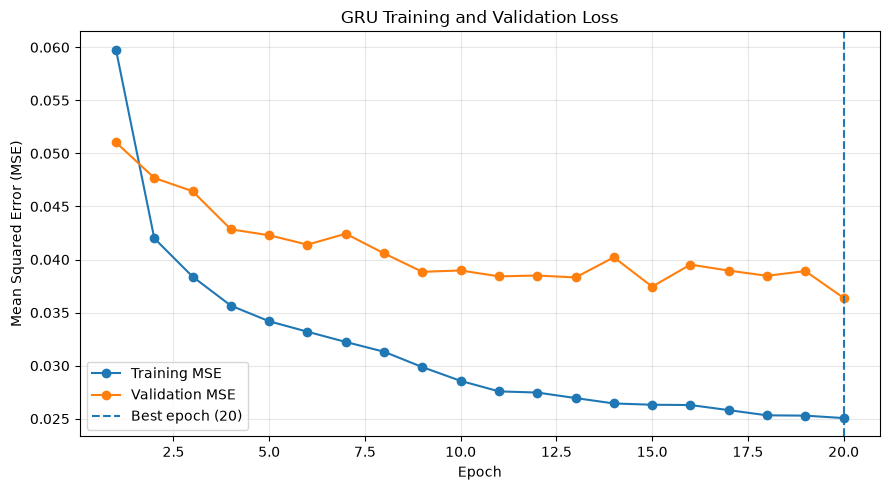

In [18]:
# Plot GRU training and validation losses
epochs = range(1, len(gru_history["train_loss"]) + 1)

best_epoch = (
    gru_history["val_loss"].index(
        min(gru_history["val_loss"])
    ) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    gru_history["train_loss"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    epochs,
    gru_history["val_loss"],
    marker="o",
    label="Validation MSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("GRU Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Restore the GRU weights from the best validation epoch
gru_model.load_state_dict(
    torch.load(
        gru_checkpoint,
        map_location=device,
        weights_only=True
    )
)

# Switch to evaluation mode
gru_model.eval()

print("Best GRU checkpoint loaded successfully.")
print("Checkpoint:", gru_checkpoint)

Best GRU checkpoint loaded successfully.
Checkpoint: c:\Users\sy_be\Projects\Electricity-Forecasting-PyTorch\models\best_gru.pt


In [20]:
# Generate GRU predictions on the test dataset
gru_predictions, gru_targets = generate_predictions(
    model=gru_model,
    data_loader=test_loader,
    device=device,
)

# Calculate metrics in the original consumption scale
gru_metrics = calculate_metrics(
    predictions=gru_predictions,
    targets=gru_targets,
    scaler=scaler,
)

# Display results
print("GRU Test Results")
print("----------------")
print("Predictions shape:", gru_predictions.shape)
print("Targets shape:", gru_targets.shape)

for metric, value in gru_metrics.items():
    print(f"{metric}: {value:.4f}")

GRU Test Results
----------------
Predictions shape: (35040, 1)
Targets shape: (35040, 1)
MAE: 0.1928
MSE: 0.1047
RMSE: 0.3236


In [21]:
from sklearn.metrics import mean_squared_error

# Generate GRU predictions on the validation dataset
gru_val_predictions, gru_val_targets = generate_predictions(
    model=gru_model,
    data_loader=val_loader,
    device=device,
)

# Calculate validation MSE in standardised units
gru_val_mse = mean_squared_error(
    gru_val_targets,
    gru_val_predictions
)

# Calculate test MSE in standardised units
gru_test_mse = mean_squared_error(
    gru_targets,
    gru_predictions
)

print(f"GRU validation MSE (scaled): {gru_val_mse:.6f}")
print(f"GRU test MSE (scaled):       {gru_test_mse:.6f}")
print(f"Expected validation MSE:    {min(gru_history['val_loss']):.6f}")

GRU validation MSE (scaled): 0.036387
GRU test MSE (scaled):       0.089179
Expected validation MSE:    0.036387


In [22]:
# Compare consumption distributions across the three periods
df = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "electricity_full.csv",
    parse_dates=["timestamp"]
)

df["period"] = pd.cut(
    df["timestamp"],
    bins=pd.to_datetime([
        "2011-01-01",
        "2013-01-01",
        "2014-01-01",
        "2015-01-01"
    ]),
    labels=["Training", "Validation", "Test"],
    right=False
)

print(
    df.groupby("period", observed=True)["consumption"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(4)
)

            count    mean     std     min     max
period                                           
Training    70175  0.0578  1.0835 -1.4145  3.0289
Validation  35040 -0.1383  0.9884 -1.4145  2.7991
Test        35040  0.0224  0.8052 -1.4145  2.6458


## Model Performance Comparison

In [23]:
import pandas as pd

# Combine evaluation results
comparison_df = pd.DataFrame({
    "Model": ["Persistence", "RNN", "LSTM", "GRU"],
    "MAE": [
        persistence_mae,
        rnn_metrics["MAE"],
        lstm_metrics["MAE"],
        gru_metrics["MAE"],
    ],
    "MSE": [
        persistence_mse,
        rnn_metrics["MSE"],
        lstm_metrics["MSE"],
        gru_metrics["MSE"],
    ],
    "RMSE": [
        persistence_rmse,
        rnn_metrics["RMSE"],
        lstm_metrics["RMSE"],
        gru_metrics["RMSE"],
    ],
})

# Rank models by RMSE (lower is better)
comparison_df = comparison_df.sort_values(
    "RMSE"
).reset_index(drop=True)

display(comparison_df.round(4))

# Save results for the GitHub repository
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

,Model,MAE,MSE,RMSE
0,Persistence,0.0935,0.0399,0.1998
1,RNN,0.1184,0.0455,0.2133
2,LSTM,0.1313,0.0505,0.2247
3,GRU,0.1928,0.1047,0.3236


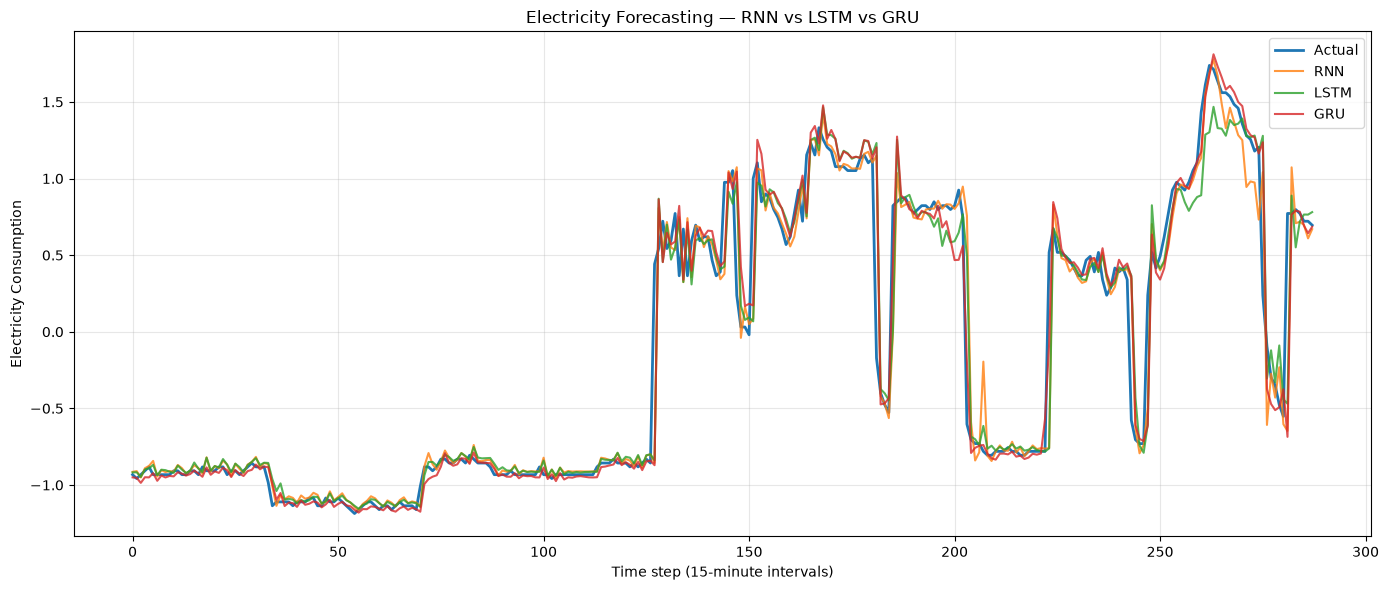

In [24]:
# Compare predictions over the first three days
n_points = 288

# Convert all predictions to original consumption units
rnn_original = scaler.inverse_transform(rnn_predictions)
lstm_original = scaler.inverse_transform(lstm_predictions)
gru_original = scaler.inverse_transform(gru_predictions)

# Actual consumption
actual = scaler.inverse_transform(rnn_targets)

# Plot comparison
plt.figure(figsize=(14, 6))

plt.plot(
    actual[:n_points, 0],
    label="Actual",
    linewidth=2,
)

plt.plot(
    rnn_original[:n_points, 0],
    label="RNN",
    alpha=0.8,
)

plt.plot(
    lstm_original[:n_points, 0],
    label="LSTM",
    alpha=0.8,
)

plt.plot(
    gru_original[:n_points, 0],
    label="GRU",
    alpha=0.8,
)

plt.xlabel("Time step (15-minute intervals)")
plt.ylabel("Electricity Consumption")
plt.title("Electricity Forecasting — RNN vs LSTM vs GRU")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save figure for GitHub
plt.savefig(
    results_dir / "forecast_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()